In [1]:
import numpy as np
import pandas as pd
import abcd_helper as abcd
from abcd_helper.config import DATA_DIR, PROCESSED_DATA_DIR

# Set plot styling
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 35)

# logging
import logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
logger = logging.getLogger(__name__)


In [2]:
df_convos = abcd.load_conversations()
logger.info(f"Loaded conversations table: {len(df_convos)} rows")

df_turns = abcd.load_turns()
logger.info(f"Loaded turns table: {len(df_turns)} rows")

extracted_slots_path = PROCESSED_DATA_DIR / "customer_slots_extracted_run_02.parquet"
logger.info(f"Loading NLP-extracted slots from {extracted_slots_path}")
df_extracted_slots = pd.read_parquet(extracted_slots_path)
logger.info(f"\tLoaded NLP-extracted slots table: {len(df_extracted_slots)} rows")

df_schemas = abcd.load_intent_slots(as_df=True)
logger.info(f"Loaded intent slots schema: {len(df_schemas)} rows")

INFO: Loaded conversations table: 10042 rows
INFO: Loaded turns table: 220983 rows
INFO: Loading NLP-extracted slots from /Users/ridho-akbar/Projects/data-science/projects/nlp-dialogue-state-tracking/data/processed/customer_slots_extracted_run_02.parquet
INFO: 	Loaded NLP-extracted slots table: 89372 rows
INFO: Loaded intent slots schema: 55 rows


In [3]:
from data_science.features.dst import extract_dst_features_batch
from data_science.features.ast import extract_ast_features_batch

df_dst_features = extract_dst_features_batch(
    df_convos=df_convos,
    df_slots=df_extracted_slots,
    df_schemas=df_schemas
)

df_ast_features = extract_ast_features_batch(
    df_convos=df_convos,
    df_turns=df_turns,
    df_slots=df_extracted_slots
)


dst_all_features = ["mandatory_slot_coverage", "all_mandatory_slots_filled", "unused_slot_ratio",
                    "slot_filling_latency", "upfront_slot_density", "slot_repetition_count",
                    "total_slots_disclosed", "mandatory_slots_satisfied", "mandatory_slots_count"]

ast_all_features = ["num_actions_taken", "num_canonical_actions", "sop_edit_distance_raw",
                    "sop_edit_distance_norm", "action_thrashing_count", "action_count_ratio",
                    "action_count_delta", "premature_action_attempts", "action_execution_latency_mean"]

df_all_nlp_features = (
    df_convos[['convo_id', 'resolved']].merge(
        df_dst_features, how='inner', on=['convo_id'], 
    ).merge(
        df_ast_features, how='inner', on=['convo_id'], 
    )
)

## DST Features Inspection

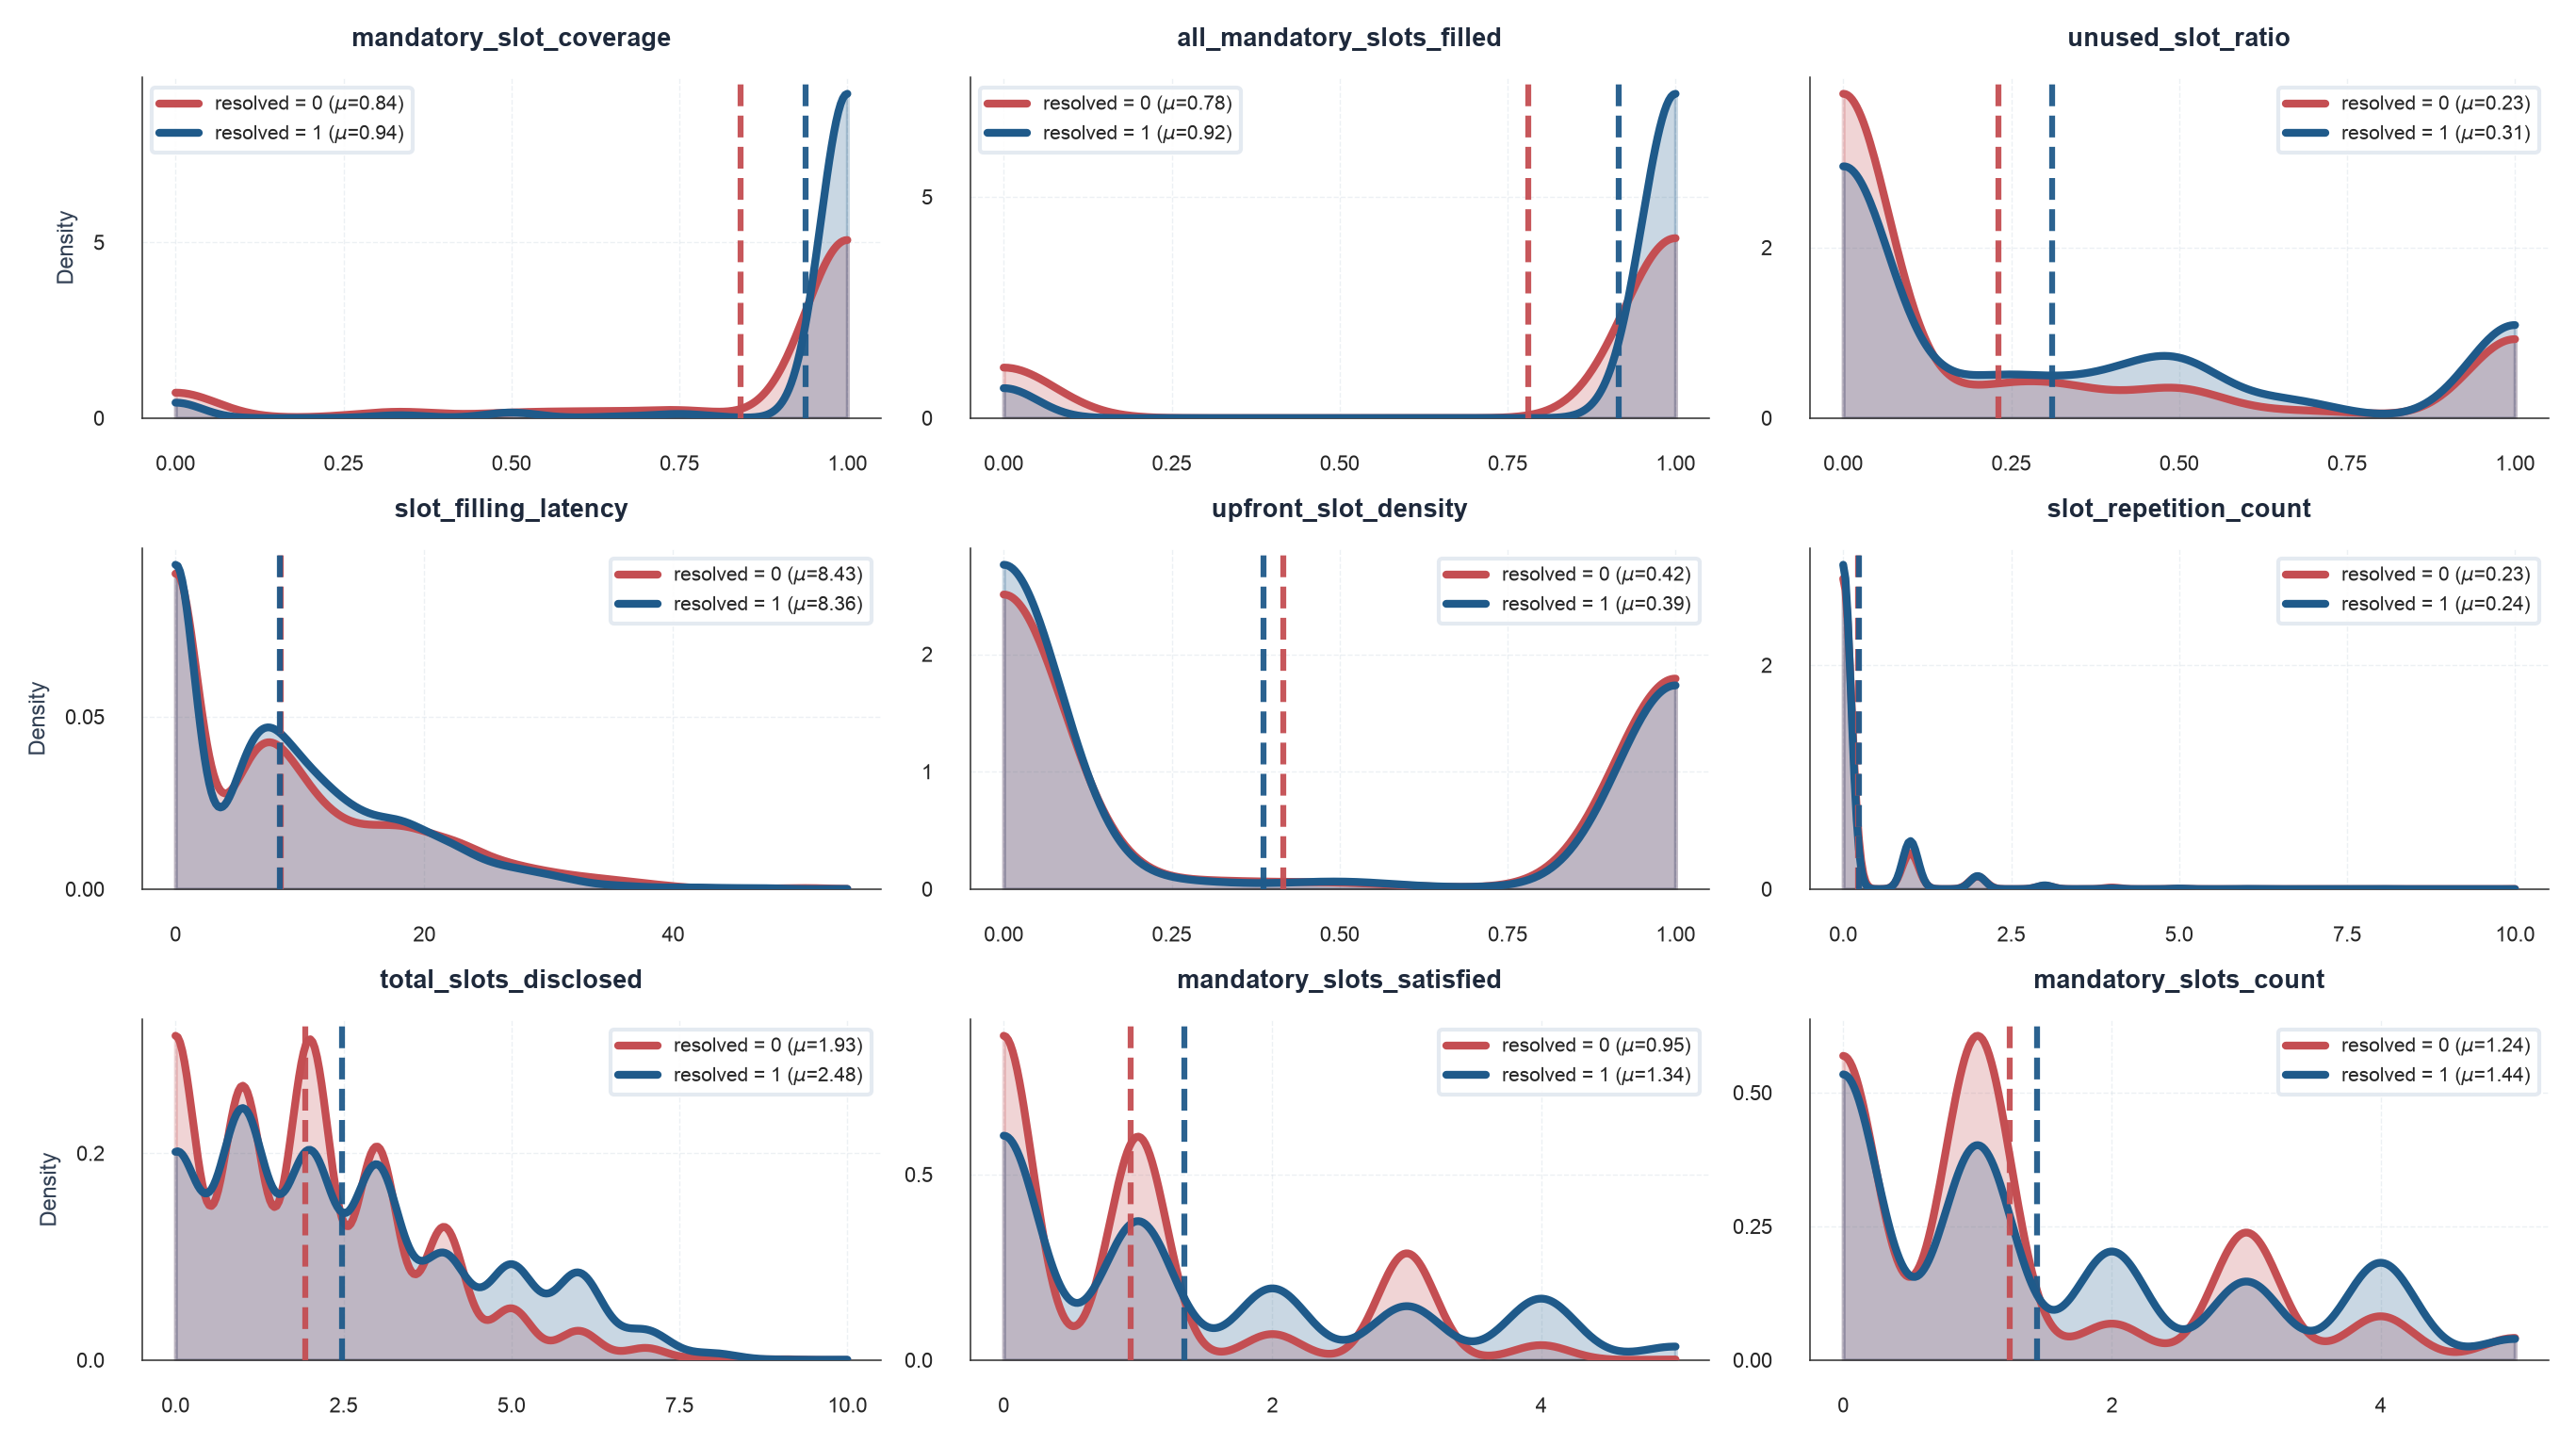

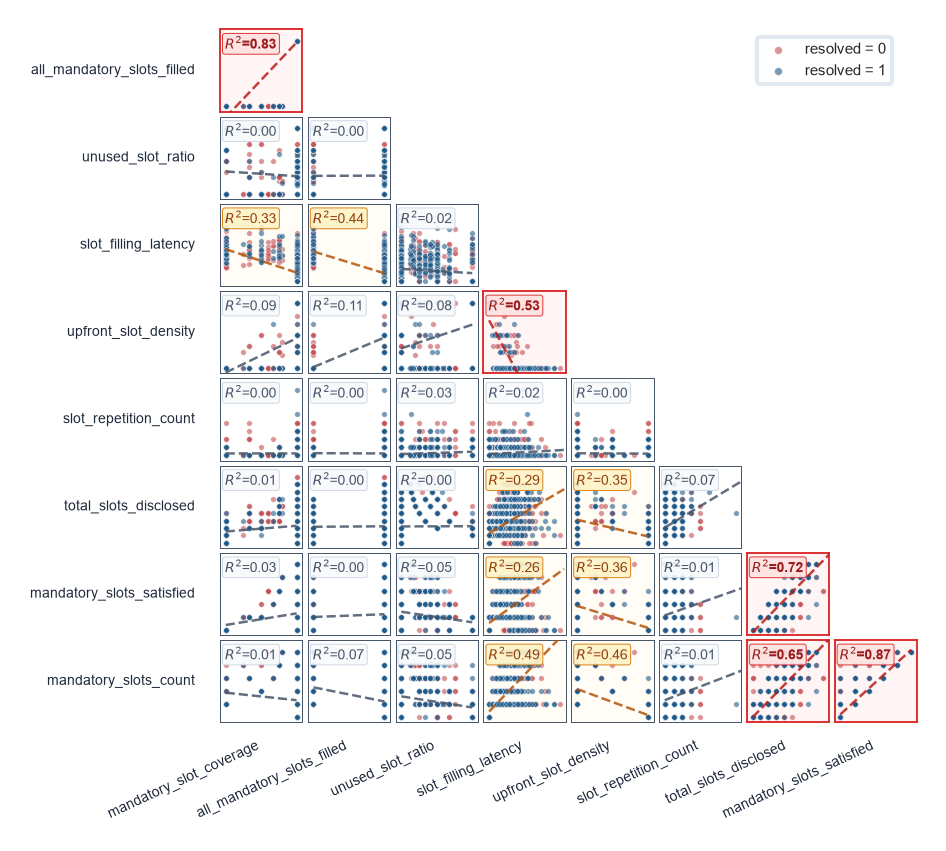

In [4]:
from data_science import visualisations as viz 

# value distribution
fig, axes = viz.plot_distribution(
    x=df_all_nlp_features,
    x_columns=dst_all_features,
    groupby="resolved",
    kind="kde",
    density=True,
    figsize=(9, 5), dpi=300
)
plt.show()

# cross correlation
fig, axes = viz.plot_correlation_matrix(
    x=df_all_nlp_features,
    x_columns=dst_all_features,
    groupby="resolved",
    figsize=(3, 3), dpi=300
)
plt.show()

# AST Features Inspection

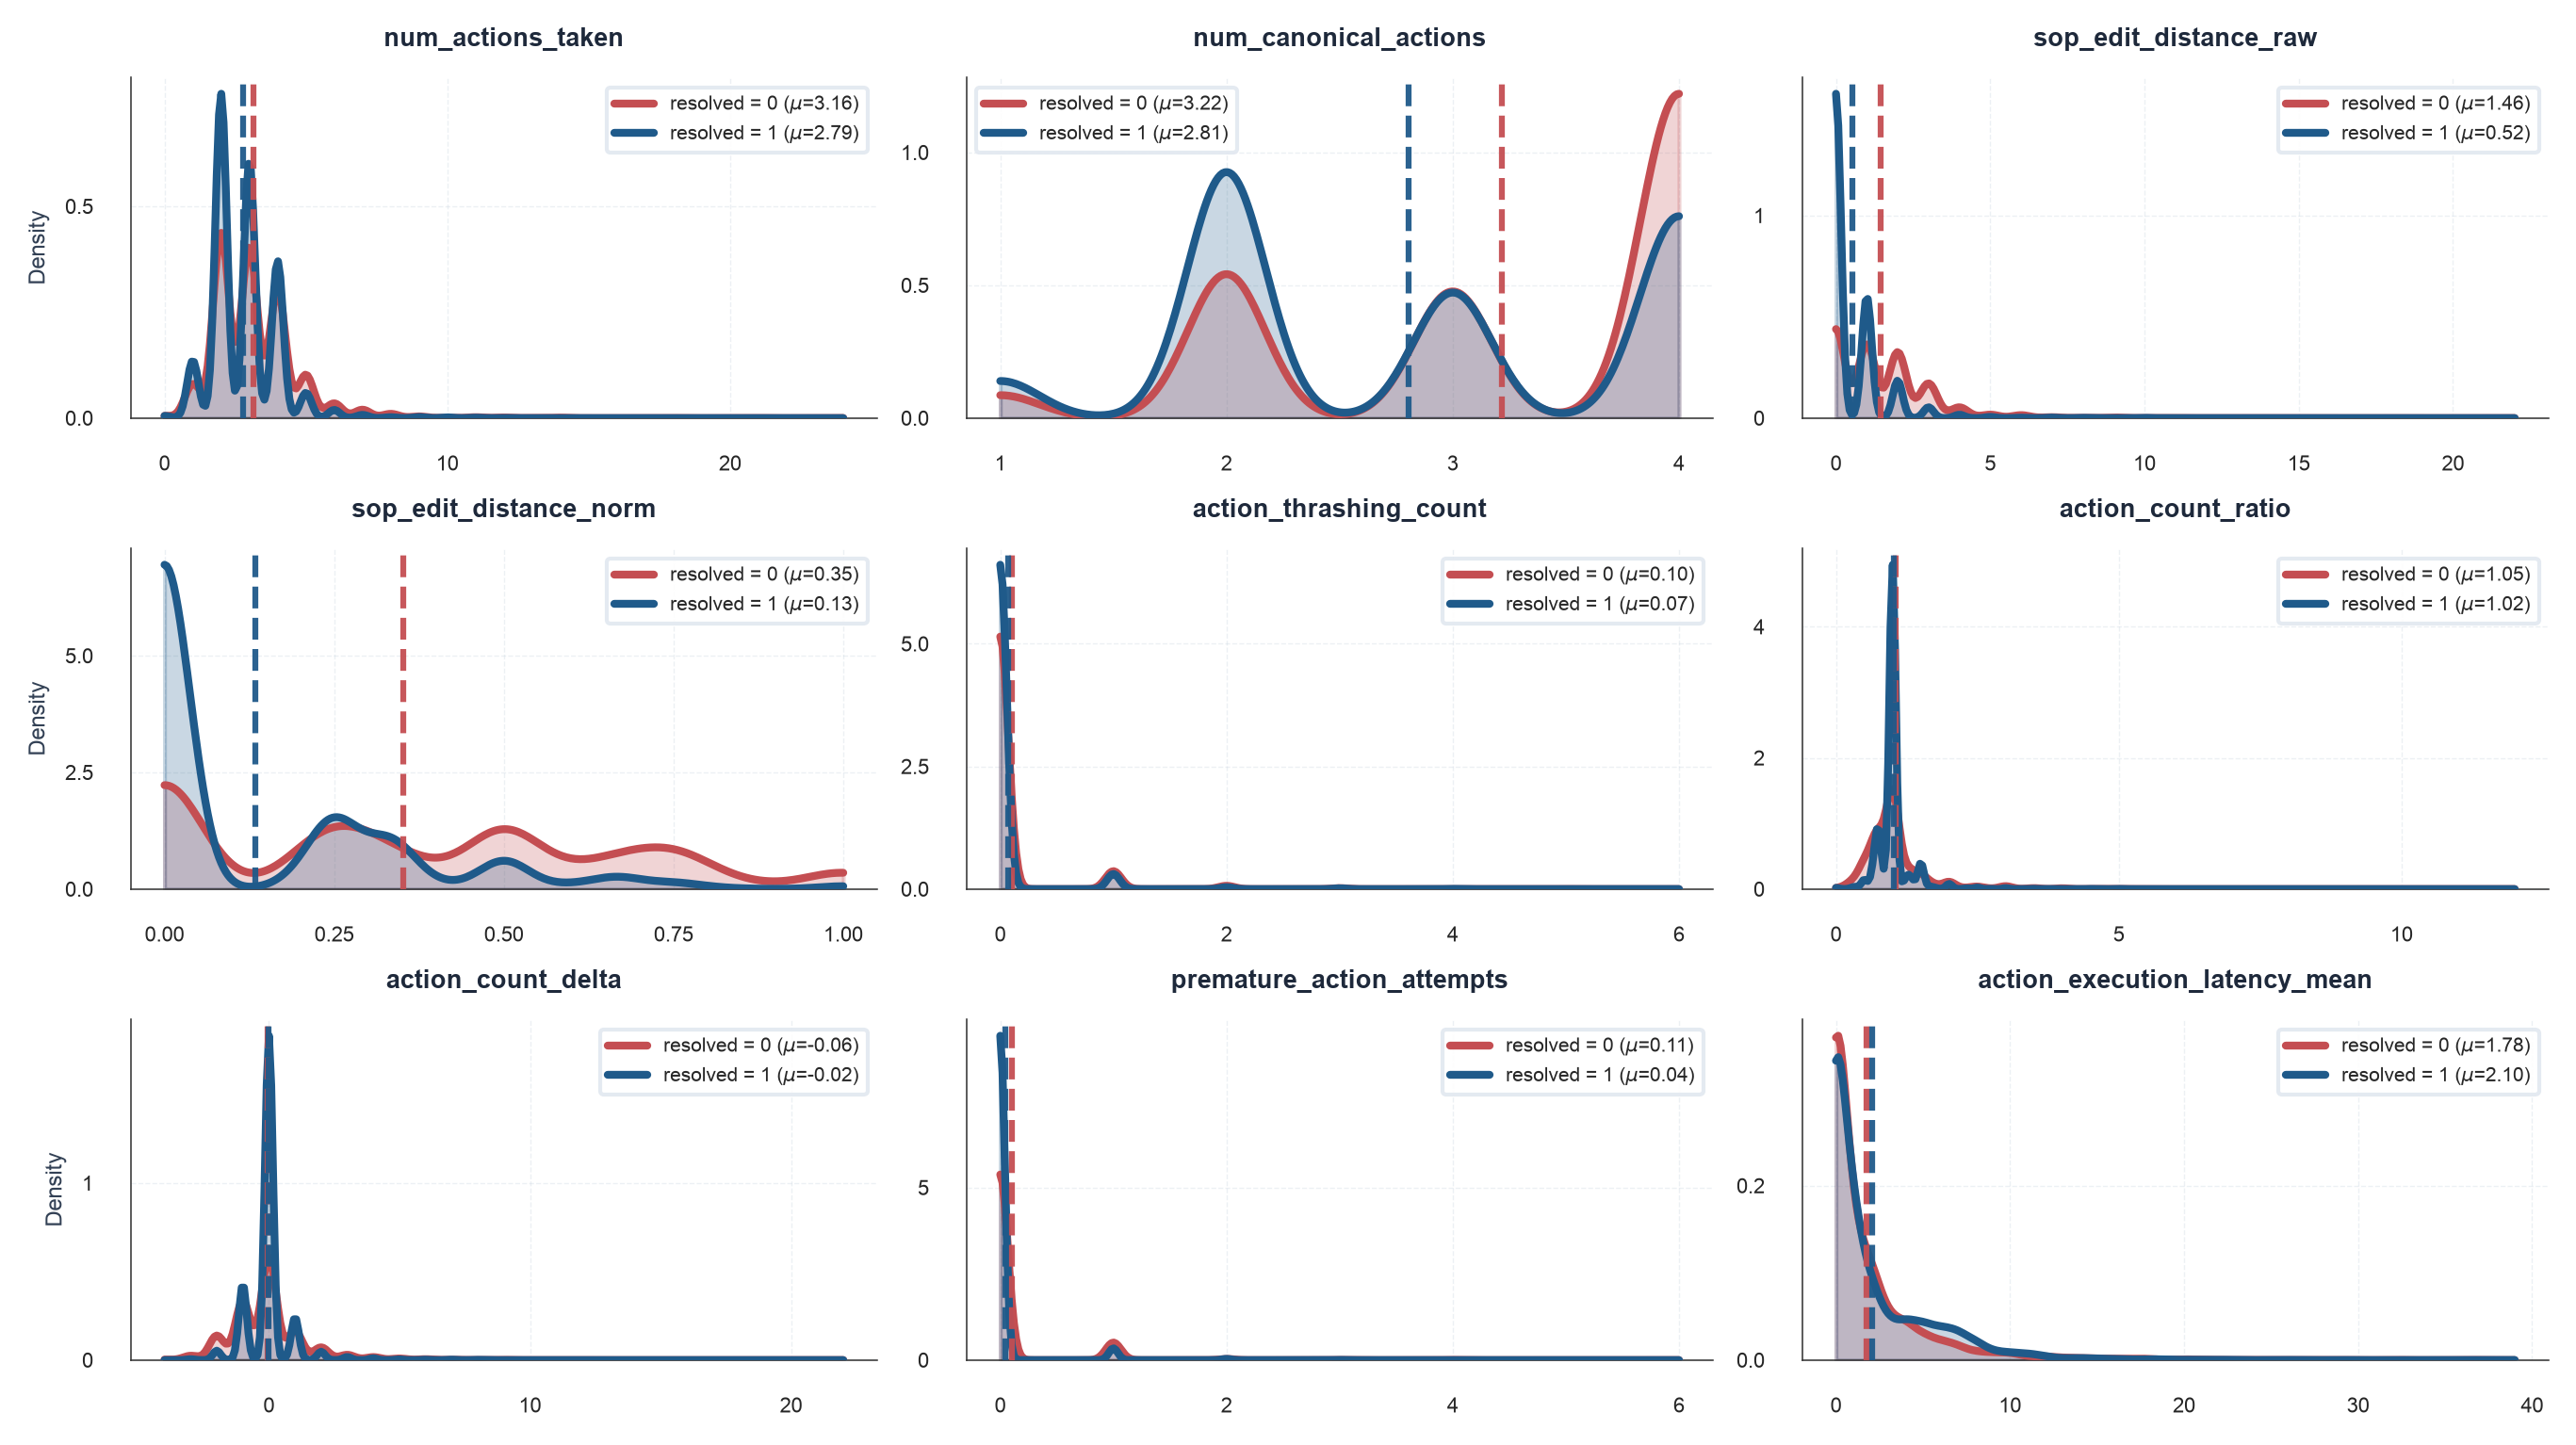

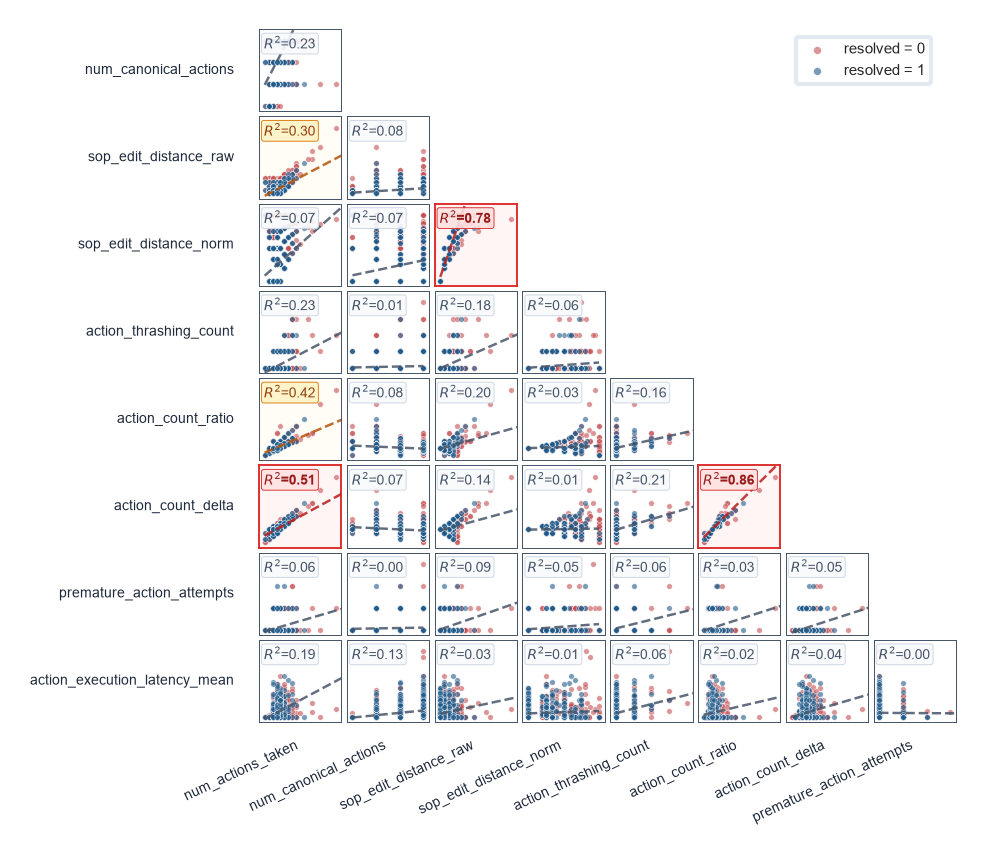

In [6]:
# value distribution
fig, axes = viz.plot_distribution(
    x=df_all_nlp_features,
    x_columns=ast_all_features,
    groupby="resolved",
    kind="kde",
    density=True,
    figsize=(9, 5), dpi=300
)
plt.show()

# cross correlation
fig, axes = viz.plot_correlation_matrix(
    x=df_all_nlp_features,
    x_columns=ast_all_features,
    groupby="resolved",
    figsize=(3, 3), dpi=300
)
plt.show()

In [9]:
from data_science.features.encodings import one_hot_encode 

dst_selected_features = ["mandatory_slot_coverage", "all_mandatory_slots_filled", "unused_slot_ratio",
                         "slot_filling_latency", "upfront_slot_density", "slot_repetition_count",
                         "total_slots_disclosed", "mandatory_slots_count"]

ast_selected_features = ["num_canonical_actions", "sop_edit_distance_norm", "action_thrashing_count",
                         "action_count_delta", "premature_action_attempts", "action_execution_latency_mean"]

df_nlp_features = df_all_nlp_features[['convo_id'] + dst_selected_features + ast_selected_features].copy()

df_context_features = df_convos[["convo_id", "resolved", "flow", "member_level", "num_turns"]].copy()
df_context_features["share_customer_turns"] = (
    df_convos["num_customer_turns"] / df_convos["num_turns"]
)
df_context_features["num_order_products"] = (
    df_convos["order_products"].str.split(",").str.len().fillna(0).astype(int)
)
df_context_features = one_hot_encode(                                                                                                                                      
    df_context_features,
    columns=["flow", "member_level"],
    drop_original_columns=True,
    drop_first=True,
    reference_categories={"flow":"account_access", "member_level": "guest"}
) 

df_ols_features = (
    df_context_features
    .merge(df_nlp_features, how='inner', on='convo_id')
)

df_ols_features.head()

,convo_id,resolved,num_turns,share_customer_turns,num_order_products,flow_manage_account,flow_order_issue,flow_product_defect,flow_purchase_dispute,flow_shipping_issue,flow_single_item_query,flow_storewide_query,flow_subscription_inquiry,flow_troubleshoot_site,member_level_bronze,member_level_gold,member_level_silver,mandatory_slot_coverage,all_mandatory_slots_filled,unused_slot_ratio,slot_filling_latency,upfront_slot_density,slot_repetition_count,total_slots_disclosed,mandatory_slots_count,num_canonical_actions,sop_edit_distance_norm,action_thrashing_count,action_count_delta,premature_action_attempts,action_execution_latency_mean
0,3592,0,29,0.448276,1,0,0,1,0,0,0,0,0,0,1,0,0,0.75,0,0.25,29.0,0.000000,0,4,4,4,0.25,0,-1,0,7.0
1,9489,0,21,0.476190,1,0,0,1,0,0,0,0,0,0,0,1,0,1.00,1,0.00,8.0,0.000000,0,3,3,2,0.00,0,0,0,2.0
2,3695,1,22,0.363636,0,0,0,0,0,0,0,1,0,0,1,0,0,1.00,1,1.00,0.0,1.000000,0,1,0,2,0.00,0,0,0,0.0
3,5798,1,23,0.304348,3,0,0,0,0,1,0,0,0,0,0,0,1,1.00,1,0.40,12.0,0.333333,0,5,3,3,0.00,0,0,0,1.0
4,3647,1,23,0.565217,3,0,0,0,0,0,0,1,0,0,0,0,0,1.00,1,0.00,0.0,1.000000,0,0,0,2,0.00,0,0,0,0.0
